### Align Samples
pymaftools: https://github.com/xu62u4u6/pymaftools/blob/main/pymaftools/core/Clustering.py

In [1]:
#conda activate TLS
#pip uninstall pymaftools
#pip install --no-cache-dir git+https://github.com/xu62u4u6/pymaftools.git
from pymaftools import *
import sys
sys.path.append("/home/data/data_YM313112004/TLS_model/utils/")
random_seed = 42
cancer_type = "PAAD"

In [2]:
# 不用重啟 kernel，Notebook 就會自動載入更新後的函式
%load_ext autoreload
%autoreload 2

In [ ]:
import os
os.makedirs(f"./results/{cancer_type}/table", exist_ok=True)

#### RNA

In [196]:
df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/raw_matrix/RNA_tomodel.csv")
df.rename(columns={'Unnamed: 0': 'ensg_name'}, inplace=True)
#df = df[~df.index.str.contains("PAR_Y")]  # 移除 Pseudoautosomal Region Y
df

,ensg_name,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,...,TCGA-ZD-A8I3-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y2-01A,TCGA-ZH-A8Y4-01A,TCGA-ZH-A8Y5-01A,TCGA-ZH-A8Y6-01A,TCGA-ZH-A8Y8-01A,TCGA-ZU-A8S4-01A,gene_name,gene_type
0,ENSG00000000003.15,5.577069,6.124378,5.089998,6.105756,6.431737,5.508219,6.993814,4.926683,5.665532,...,6.593797,5.631288,7.281439,5.862119,7.253354,3.342398,6.144838,5.233106,TSPAN6,protein_coding
1,ENSG00000000005.6,0.060601,0.069977,0.139862,0.074231,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.078746,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,TNMD,protein_coding
2,ENSG00000000419.13,6.577149,6.267335,6.418674,6.348643,6.659800,6.298851,6.168482,6.352455,5.152155,...,6.392594,6.250543,6.784777,6.048459,7.055845,6.312772,7.211966,6.848891,DPM1,protein_coding
3,ENSG00000000457.14,2.524440,2.846393,2.623001,3.493622,3.563780,4.527877,2.114900,2.822118,2.413811,...,3.128953,4.389601,3.661008,3.019044,4.522495,3.759678,3.593174,2.474773,SCYL3,protein_coding
4,ENSG00000000460.17,1.727223,1.845028,1.766553,1.755785,2.420779,1.944071,0.932893,1.685267,1.658417,...,2.439597,3.011048,2.874561,2.076798,2.539556,1.907660,2.536724,2.648627,C1orf112,protein_coding
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60655,ENSG00000288669.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.044184,0.000000,0.104873,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.021053,0.000000,0.048934,0.000000,AC008763.4,protein_coding
60656,ENSG00000288670.1,2.753519,4.794525,2.973942,3.670999,3.980967,4.799771,3.644525,3.916649,3.449258,...,4.473664,4.579603,4.573950,4.631197,6.028998,4.168554,4.388107,3.441961,AL592295.6,lncRNA
60657,ENSG00000288671.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,AC006486.3,protein_coding
60658,ENSG00000288674.1,0.037453,0.043345,0.044324,0.057277,0.116631,0.124725,0.067226,0.022332,0.039419,...,0.153027,0.182438,0.133432,0.158596,0.249263,0.124725,0.128161,0.051442,AL391628.1,protein_coding


In [197]:
# 計算每個 gene_name 出現次數
gene_counts = df["gene_name"].value_counts()

# 找出重複的 gene_name
duplicate_names = gene_counts[gene_counts > 1].index
duplicate_names

Index(['Y_RNA', 'Metazoa_SRP', 'U3', 'U6', 'SNORA70', 'U8', 'U2', '5S_rRNA',
       'SNORA72', 'SNORA63',
       ...
       'HERC2P7', 'SNORA16A', 'SNORA17B', 'MIR6089', 'SNORD22', 'SNORD3D',
       'SCARNA4', 'AL732314.4', 'AL732314.10', 'SMIM40'],
      dtype='str', name='gene_name', length=110)

In [198]:
# 對重複的 gene_name 加 #1、#2，唯一的保持不變
def make_unique_name(row):
    if row["gene_name"] in duplicate_names:
        return f"{row['gene_name']}#{row['dup_count'] + 1}"
    else:
        return row["gene_name"]

# 為重複的 gene_name 做編號
df["dup_count"] = df.groupby("gene_name").cumcount()
df["unique_name"] = df.apply(make_unique_name, axis=1)
df

,ensg_name,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,...,TCGA-ZH-A8Y2-01A,TCGA-ZH-A8Y4-01A,TCGA-ZH-A8Y5-01A,TCGA-ZH-A8Y6-01A,TCGA-ZH-A8Y8-01A,TCGA-ZU-A8S4-01A,gene_name,gene_type,dup_count,unique_name
0,ENSG00000000003.15,5.577069,6.124378,5.089998,6.105756,6.431737,5.508219,6.993814,4.926683,5.665532,...,7.281439,5.862119,7.253354,3.342398,6.144838,5.233106,TSPAN6,protein_coding,0,TSPAN6
1,ENSG00000000005.6,0.060601,0.069977,0.139862,0.074231,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,TNMD,protein_coding,0,TNMD
2,ENSG00000000419.13,6.577149,6.267335,6.418674,6.348643,6.659800,6.298851,6.168482,6.352455,5.152155,...,6.784777,6.048459,7.055845,6.312772,7.211966,6.848891,DPM1,protein_coding,0,DPM1
3,ENSG00000000457.14,2.524440,2.846393,2.623001,3.493622,3.563780,4.527877,2.114900,2.822118,2.413811,...,3.661008,3.019044,4.522495,3.759678,3.593174,2.474773,SCYL3,protein_coding,0,SCYL3
4,ENSG00000000460.17,1.727223,1.845028,1.766553,1.755785,2.420779,1.944071,0.932893,1.685267,1.658417,...,2.874561,2.076798,2.539556,1.907660,2.536724,2.648627,C1orf112,protein_coding,0,C1orf112
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60655,ENSG00000288669.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.044184,0.000000,0.104873,0.000000,...,0.000000,0.000000,0.021053,0.000000,0.048934,0.000000,AC008763.4,protein_coding,0,AC008763.4
60656,ENSG00000288670.1,2.753519,4.794525,2.973942,3.670999,3.980967,4.799771,3.644525,3.916649,3.449258,...,4.573950,4.631197,6.028998,4.168554,4.388107,3.441961,AL592295.6,lncRNA,0,AL592295.6
60657,ENSG00000288671.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,AC006486.3,protein_coding,0,AC006486.3
60658,ENSG00000288674.1,0.037453,0.043345,0.044324,0.057277,0.116631,0.124725,0.067226,0.022332,0.039419,...,0.133432,0.158596,0.249263,0.124725,0.128161,0.051442,AL391628.1,protein_coding,0,AL391628.1


In [199]:
sample_metadata_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/sample_sheet_RNA.csv", index_col=0)
foldchange_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/res_df_pc.csv", index_col=0)  # 篩選完 protein-coding 再做 DESeq2?

# 將 foldchange_df 的 index 改成 unique name
fc_hugo = pd.merge(foldchange_df, df[["ensg_name", "unique_name"]], left_index=True, right_on="ensg_name", how="left")
fc_hugo = fc_hugo.set_index("unique_name")
fc_hugo

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,change,ensg_name
unique_name,,,,,,,,
CMA1,8.046287,5.135040,0.870138,5.901406,3.604171e-09,0.000063,UP,ENSG00000092009.10
IL5RA,6.852948,3.166009,0.556690,5.687201,1.291382e-08,0.000113,UP,ENSG00000091181.20
FCMR,221.780684,2.725689,0.489349,5.570025,2.547032e-08,0.000143,UP,ENSG00000162894.12
NIBAN3,68.632054,3.626112,0.656105,5.526726,3.262624e-08,0.000143,UP,ENSG00000167483.19
ADGRL3,53.103968,2.747844,0.501455,5.479743,4.259446e-08,0.000149,UP,ENSG00000150471.16
...,...,...,...,...,...,...,...,...
AC119733.1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,ENSG00000288654.1
AC020765.6,0.322774,-0.743234,2.672058,-0.278150,7.808969e-01,NaN,NOT,ENSG00000288656.1
AL451106.1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,ENSG00000288661.1


In [200]:
df = df.set_index("unique_name")
df.index.name = None

all_table = PivotTable(df.drop(["ensg_name","gene_name", "gene_type","dup_count"], axis=1))
all_table = all_table.add_feature_metadata(pd.DataFrame(df["ensg_name"]), fill_value=np.nan)
all_table = all_table.add_feature_metadata(pd.DataFrame(df["gene_name"]), fill_value=np.nan)   ## 可以加上是否為DEG、MCPcounter genes、TLS marker genes
all_table = all_table.add_feature_metadata(pd.DataFrame(df["gene_type"]), fill_value=np.nan)  
all_table = all_table.add_feature_metadata(fc_hugo, fill_value=np.nan, force=True)
all_table = all_table.add_sample_metadata(sample_metadata_df, fill_value=np.nan)

# 強制依 data index 排序 feature_metadata（若有缺或多則會留下 NaN）
all_table.feature_metadata = all_table.feature_metadata.reindex(all_table.index)
all_table

Overwriting existing columns: ['ensg_name']


,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,TCGA-W5-AA2O-01A,...,TCGA-WD-A7RX-01A,TCGA-YR-A95A-01A,TCGA-ZD-A8I3-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y2-01A,TCGA-ZH-A8Y4-01A,TCGA-ZH-A8Y5-01A,TCGA-ZH-A8Y6-01A,TCGA-ZH-A8Y8-01A,TCGA-ZU-A8S4-01A
TSPAN6,5.577069,6.124378,5.089998,6.105756,6.431737,5.508219,6.993814,4.926683,5.665532,5.638529,...,7.127350,6.980799,6.593797,5.631288,7.281439,5.862119,7.253354,3.342398,6.144838,5.233106
TNMD,0.060601,0.069977,0.139862,0.074231,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.062536,0.467279,0.078746,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
DPM1,6.577149,6.267335,6.418674,6.348643,6.659800,6.298851,6.168482,6.352455,5.152155,6.587676,...,6.115874,5.915277,6.392594,6.250543,6.784777,6.048459,7.055845,6.312772,7.211966,6.848891
SCYL3,2.524440,2.846393,2.623001,3.493622,3.563780,4.527877,2.114900,2.822118,2.413811,3.354960,...,3.496309,2.957190,3.128953,4.389601,3.661008,3.019044,4.522495,3.759678,3.593174,2.474773
C1orf112,1.727223,1.845028,1.766553,1.755785,2.420779,1.944071,0.932893,1.685267,1.658417,2.290601,...,2.331390,1.138094,2.439597,3.011048,2.874561,2.076798,2.539556,1.907660,2.536724,2.648627
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC008763.4,0.000000,0.000000,0.000000,0.000000,0.000000,0.044184,0.000000,0.104873,0.000000,0.054779,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.021053,0.000000,0.048934,0.000000
AL592295.6,2.753519,4.794525,2.973942,3.670999,3.980967,4.799771,3.644525,3.916649,3.449258,4.356369,...,3.966015,4.256935,4.473664,4.579603,4.573950,4.631197,6.028998,4.168554,4.388107,3.441961
AC006486.3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AL391628.1,0.037453,0.043345,0.044324,0.057277,0.116631,0.124725,0.067226,0.022332,0.039419,0.132643,...,0.131194,0.033511,0.153027,0.182438,0.133432,0.158596,0.249263,0.124725,0.128161,0.051442


In [201]:
all_table.to_sqlite(db_path=f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/rna_table_full.sqlite")

[PivotTable] saved to /home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table_full.sqlite


#### DNA Methylation

In [70]:
df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/raw_matrix/meth_tomodel.csv")
df.rename(columns={'Unnamed: 0': 'cpg_name'}, inplace=True)
#df = df[~df.index.str.contains("PAR_Y")]  # 移除 Pseudoautosomal Region Y
df = df.set_index("cpg_name")
df.index.name = None
df

,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,TCGA-W5-AA2O-01A,...,TCGA-WD-A7RX-01A,TCGA-YR-A95A-01A,TCGA-ZD-A8I3-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y2-01A,TCGA-ZH-A8Y4-01A,TCGA-ZH-A8Y5-01A,TCGA-ZH-A8Y6-01A,TCGA-ZH-A8Y8-01A,TCGA-ZU-A8S4-01A
cg00000957,0.914467,0.964118,0.935515,0.896655,0.923181,0.955650,0.917427,0.914627,0.963401,0.906934,...,0.950082,0.943425,0.943403,0.937359,0.927106,0.937067,0.968944,0.643925,0.951387,0.903832
cg00001349,0.892140,0.959835,0.929443,0.950708,0.946888,0.986946,0.952435,0.909502,0.969842,0.949593,...,0.934764,0.917786,0.954795,0.962642,0.959478,0.967680,0.976767,0.828893,0.916495,0.681102
cg00001583,0.043102,0.014038,0.023186,0.020863,0.030877,0.011801,0.019570,0.023317,0.732893,0.010674,...,0.025870,0.013972,0.015171,0.019679,0.016582,0.017344,0.008034,0.020993,0.019280,0.011805
cg00002028,0.025113,0.017782,0.042395,0.030358,0.029874,0.021601,0.028156,0.029968,0.033784,0.022046,...,0.034197,0.019127,0.027411,0.038291,0.024670,0.033407,0.018024,0.028894,0.027371,0.013191
cg00002719,0.061112,0.445368,0.052069,0.748178,0.057514,0.110320,0.591914,0.178832,0.875127,0.205601,...,0.580035,0.034032,0.071669,0.922455,0.629271,0.814879,0.575649,0.036375,0.029014,0.021697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ch.22.43177094F,0.026340,0.018366,0.025867,0.019925,0.020794,0.018131,0.039824,0.018230,0.023072,0.016207,...,0.020751,0.016469,0.022670,0.030444,0.015222,0.020161,0.013222,0.030940,0.018641,0.017342
ch.22.46830341F,0.032064,0.020335,0.029231,0.031238,0.034131,0.023465,0.039456,0.027296,0.030430,0.022359,...,0.034448,0.017327,0.027087,0.031723,0.028012,0.033562,0.016953,0.036657,0.019703,0.025144
ch.22.1008279F,0.076171,0.038777,0.013091,0.069436,0.030270,0.038948,0.066381,0.057554,0.054699,0.045158,...,0.072209,0.005467,0.015673,0.057342,0.036375,0.046007,0.040090,0.054481,0.060375,0.045844
ch.22.47579720R,0.055007,0.085149,0.077778,0.074135,0.059112,0.053409,0.071230,0.047972,0.070609,0.066121,...,0.062500,0.049209,0.075758,0.070498,0.048019,0.084169,0.055358,0.072981,0.105296,0.062890


In [71]:
# 計算整個 DataFrame 中的 missing value 數量
missing_values_count = df.isna().sum().sum()
print(f"Total missing values: {missing_values_count}")

# 移除包含缺失值的行
df_new = df.dropna()
print(f"Original shape: {df.shape}")
print(f"Cleaned shape: {df_new.shape}")

Total missing values: 0
Original shape: (388301, 35)
Cleaned shape: (388301, 35)


In [72]:
sample_metadata_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/sample_sheet_meth.csv", index_col=0)
anno_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/meth_anno_tomodel.csv", index_col=0)
dmp_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/meth_dmp_tomodel.csv", index_col=0)

all_table = PivotTable(df_new)
all_table = all_table.add_feature_metadata(anno_df, fill_value=np.nan)  ## 可以加上是否為 MCPcounter genes、TLS marker genes
all_table = all_table.add_feature_metadata(dmp_df, fill_value=np.nan)
all_table = all_table.add_sample_metadata(sample_metadata_df, fill_value=np.nan)

# 強制依 data index 排序 feature_metadata（若有缺或多則會留下 NaN）
all_table.feature_metadata = all_table.feature_metadata.reindex(all_table.index)
all_table

/tmp/ipykernel_2626338/1433376493.py:2: DtypeWarning: Columns (0: Type, 1: Color, 2: Probe_rs) have mixed types. Specify dtype option on import or set low_memory=False.
  anno_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/meth_anno_tomodel.csv", index_col=0)


,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,TCGA-W5-AA2O-01A,...,TCGA-WD-A7RX-01A,TCGA-YR-A95A-01A,TCGA-ZD-A8I3-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y2-01A,TCGA-ZH-A8Y4-01A,TCGA-ZH-A8Y5-01A,TCGA-ZH-A8Y6-01A,TCGA-ZH-A8Y8-01A,TCGA-ZU-A8S4-01A
cg00000957,0.914467,0.964118,0.935515,0.896655,0.923181,0.955650,0.917427,0.914627,0.963401,0.906934,...,0.950082,0.943425,0.943403,0.937359,0.927106,0.937067,0.968944,0.643925,0.951387,0.903832
cg00001349,0.892140,0.959835,0.929443,0.950708,0.946888,0.986946,0.952435,0.909502,0.969842,0.949593,...,0.934764,0.917786,0.954795,0.962642,0.959478,0.967680,0.976767,0.828893,0.916495,0.681102
cg00001583,0.043102,0.014038,0.023186,0.020863,0.030877,0.011801,0.019570,0.023317,0.732893,0.010674,...,0.025870,0.013972,0.015171,0.019679,0.016582,0.017344,0.008034,0.020993,0.019280,0.011805
cg00002028,0.025113,0.017782,0.042395,0.030358,0.029874,0.021601,0.028156,0.029968,0.033784,0.022046,...,0.034197,0.019127,0.027411,0.038291,0.024670,0.033407,0.018024,0.028894,0.027371,0.013191
cg00002719,0.061112,0.445368,0.052069,0.748178,0.057514,0.110320,0.591914,0.178832,0.875127,0.205601,...,0.580035,0.034032,0.071669,0.922455,0.629271,0.814879,0.575649,0.036375,0.029014,0.021697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ch.22.43177094F,0.026340,0.018366,0.025867,0.019925,0.020794,0.018131,0.039824,0.018230,0.023072,0.016207,...,0.020751,0.016469,0.022670,0.030444,0.015222,0.020161,0.013222,0.030940,0.018641,0.017342
ch.22.46830341F,0.032064,0.020335,0.029231,0.031238,0.034131,0.023465,0.039456,0.027296,0.030430,0.022359,...,0.034448,0.017327,0.027087,0.031723,0.028012,0.033562,0.016953,0.036657,0.019703,0.025144
ch.22.1008279F,0.076171,0.038777,0.013091,0.069436,0.030270,0.038948,0.066381,0.057554,0.054699,0.045158,...,0.072209,0.005467,0.015673,0.057342,0.036375,0.046007,0.040090,0.054481,0.060375,0.045844
ch.22.47579720R,0.055007,0.085149,0.077778,0.074135,0.059112,0.053409,0.071230,0.047972,0.070609,0.066121,...,0.062500,0.049209,0.075758,0.070498,0.048019,0.084169,0.055358,0.072981,0.105296,0.062890


In [73]:
all_table.to_sqlite(db_path=f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/meth_table_full.sqlite")  # 已移除 missing value

[PivotTable] saved to /home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table_full.sqlite


#### DNA Mutation

In [74]:
df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/raw_matrix/mut_matrix_tomodel.csv")
df.rename(columns={'Unnamed: 0': 'gene_name'}, inplace=True)
#df = df[~df.index.str.contains("PAR_Y")]  # 移除 Pseudoautosomal Region Y
df = df.set_index("gene_name")
df.index.name = None
df

,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,TCGA-W5-AA2O-01A,...,TCGA-WD-A7RX-01A,TCGA-YR-A95A-01A,TCGA-ZD-A8I3-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y2-01A,TCGA-ZH-A8Y4-01A,TCGA-ZH-A8Y5-01A,TCGA-ZH-A8Y6-01A,TCGA-ZH-A8Y8-01A,TCGA-ZU-A8S4-01A
DOCK7,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
LRRC71,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
OR2T12,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
APOB,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SPTBN1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SLC8A3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
ZNF423,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
SPPL2C,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
ARHGAP28,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [75]:
# 計算整個 DataFrame 中的 missing value 數量
missing_values_count = df.isna().sum().sum()
print(f"Total missing values: {missing_values_count}")

# 移除包含缺失值的行
df_new = df.dropna()
print(f"Original shape: {df.shape}")
print(f"Cleaned shape: {df_new.shape}")

Total missing values: 0
Original shape: (1410, 35)
Cleaned shape: (1410, 35)


In [76]:
sample_metadata_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/sample_sheet_mut.csv", index_col=0)
sample_variants_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/mutation_sample_metadata.csv", index_col=0)
gene_variants_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/mutation_feature_metadata.csv", index_col=0)
gene_info_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/mutation_geneinfo.csv", index_col=0)

# 檢查 Index 是否有重複
if gene_info_df.index.has_duplicates:
    print("Duplicate indices found in gene_info_df!")
    # 列出重複的 Index 及其出現次數
    duplicates = gene_info_df.index[gene_info_df.index.duplicated(keep=False)]
    print(gene_info_df.loc[duplicates])
else:
    print("No duplicate indices found.")

No duplicate indices found.


In [77]:
# 處理重複 Index：將重複的 Gene 欄位用分號合併，其他欄位保留第一筆
if gene_info_df.index.has_duplicates:  
    # 定義聚合函數：Gene 用分號連接，其他欄位取第一個值
    agg_funcs = {col: 'first' for col in gene_info_df.columns}
    agg_funcs['Gene'] = lambda x: ';'.join(x.astype(str))
    gene_info_df = gene_info_df.groupby(gene_info_df.index).agg(agg_funcs)
    print("Duplicates handled.")

In [78]:
#silent_variants_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/silentmutation_feature_metadata.csv", index_col=0)
all_table = PivotTable(df_new)
all_table = all_table.add_feature_metadata(gene_variants_df, fill_value=np.nan)  ## 可以加上是否為 MCPcounter genes、TLS marker genes
all_table = all_table.add_feature_metadata(gene_info_df, fill_value=np.nan)
#all_table = all_table.add_feature_metadata(silent_variants_df, fill_value=np.nan)
all_table = all_table.add_sample_metadata(sample_metadata_df, fill_value=np.nan)
all_table = all_table.add_sample_metadata(sample_variants_df, fill_value=np.nan)

# 強制依 data index 排序 feature_metadata（若有缺或多則會留下 NaN）
all_table.feature_metadata = all_table.feature_metadata.reindex(all_table.index)
all_table

,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,TCGA-W5-AA2O-01A,...,TCGA-WD-A7RX-01A,TCGA-YR-A95A-01A,TCGA-ZD-A8I3-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y2-01A,TCGA-ZH-A8Y4-01A,TCGA-ZH-A8Y5-01A,TCGA-ZH-A8Y6-01A,TCGA-ZH-A8Y8-01A,TCGA-ZU-A8S4-01A
DOCK7,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
LRRC71,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
OR2T12,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
APOB,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SPTBN1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SLC8A3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
ZNF423,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
SPPL2C,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
ARHGAP28,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [79]:
all_table.to_sqlite(db_path=f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/mutation_table_full.sqlite")

[PivotTable] saved to /home/data/data_YM313112004/TLS_model/results/CHOL/table/mutation_table_full.sqlite


#### CNV

Create sample sheet

In [80]:
# TLS label (只要有一個TLS = 1，就是TLS-positive)
TLS_sheet = pd.read_excel(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/TLS vs. model_filtered (TCGA-{cancer_type}).xlsx")
TLS_sheet.rename(columns={TLS_sheet.columns[6]: "Sample.ID", TLS_sheet.columns[10]: "model"}, inplace=True)
TLS_label = TLS_sheet[["Sample.ID", "TLS", "model"]]

# Group by Sample.ID and summarize TLS and model
TLS_new_label = TLS_label.groupby("Sample.ID").agg({  
    "TLS": lambda x: int((x == 1).any()),
    "model": lambda x: int((x == 1).any())
}).reset_index()

TLS_new_label

,Sample.ID,TLS,model
0,TCGA-3X-AAV9,1,0
1,TCGA-3X-AAVA,1,0
2,TCGA-3X-AAVB,0,0
3,TCGA-3X-AAVC,0,0
4,TCGA-3X-AAVE,0,0
5,TCGA-4G-AAZO,0,0
6,TCGA-4G-AAZT,0,0
7,TCGA-W5-AA2G,0,0
8,TCGA-W5-AA2I,0,0
9,TCGA-W5-AA2O,0,0


In [81]:
# Sample sheet of CNV data
gdc_data = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/gdc_sample_sheet_filtered.tsv", sep="\t", header=0)
gdc_data

# Merge with TLS_new_label
sample_sheet = (pd.merge(gdc_data, 
                        TLS_new_label, 
                        left_on="Sample ID Tumor", 
                        right_on="Sample.ID", 
                        how="inner")
                .drop(columns=["Sample.ID"])
                )

#sample_sheet.to_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/sample_sheet_cnv.csv", index=False)
sample_sheet

,File ID Tumor,File Name Tumor,Data Category Tumor,Data Type Tumor,Project ID Tumor,Case ID,Sample ID Tumor,Tissue Type Tumor,Tumor Descriptor Tumor,Specimen Type Tumor,...,Data Category Normal,Data Type Normal,Project ID Normal,Sample ID Normal,Tissue Type Normal,Tumor Descriptor Normal,Specimen Type Normal,Preservation Method Normal,TLS,model


Read CNV matrix (log2 ratio)

In [82]:
df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/raw_matrix/all_data_by_genes.txt", sep="\t")
df["gene_name"] = df["Gene Symbol"].str.split("|").str[0]
df = df.set_index("Gene Symbol")
df

,Gene ID,Cytoband,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,...,TCGA-YR-A95A-01A,TCGA-ZD-A8I3-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y2-01A,TCGA-ZH-A8Y4-01A,TCGA-ZH-A8Y5-01A,TCGA-ZH-A8Y6-01A,TCGA-ZH-A8Y8-01A,TCGA-ZU-A8S4-01A,gene_name
Gene Symbol,,,,,,,,,,,,,,,,,,,,,
DDX11L1,100287102,1p36.33,-0.158,-0.796,-0.017,0.057,0.014,-0.39,-0.598,-0.084,...,-0.758,-0.516,0.033,-0.650,-0.806,-0.889,0.000,-0.596,-0.365,DDX11L1
FAM138A|chr1,645520,1p36.33,-0.158,-0.796,-0.017,0.057,0.014,-0.39,-0.598,-0.084,...,-0.758,-0.516,0.033,-0.650,-0.806,-0.889,0.000,-0.596,-0.365,FAM138A
FAM138C|chr1,654835,1p36.33,-0.158,-0.796,-0.017,0.057,0.014,-0.39,-0.598,-0.084,...,-0.758,-0.516,0.033,-0.650,-0.806,-0.889,0.000,-0.596,-0.365,FAM138C
MIR1302-10|chr1,100422834,1p36.33,-0.158,-0.796,-0.017,0.057,0.014,-0.39,-0.598,-0.084,...,-0.758,-0.516,0.033,-0.650,-0.806,-0.889,0.000,-0.596,-0.365,MIR1302-10
MIR1302-11|chr1,100422919,1p36.33,-0.158,-0.796,-0.017,0.057,0.014,-0.39,-0.598,-0.084,...,-0.758,-0.516,0.033,-0.650,-0.806,-0.889,0.000,-0.596,-0.365,MIR1302-11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SHANK3,85358,22q13.33,-0.061,-0.059,0.226,-0.336,-0.091,-0.02,-0.497,0.241,...,-0.028,-0.027,-0.011,-0.142,-0.038,-0.026,-0.014,-0.005,-0.009,SHANK3
LOC105373100,105373100,22q13.33,-0.061,-0.059,0.226,-0.336,-0.091,-0.02,-0.497,0.241,...,-0.028,-0.027,-0.011,-0.142,-0.038,-0.026,-0.014,-0.005,-0.009,LOC105373100
ACR,49,22q13.33,-0.061,-0.059,0.226,-0.336,-0.091,-0.02,-0.497,0.241,...,-0.028,-0.027,-0.011,-0.142,-0.038,-0.026,-0.014,-0.005,-0.009,ACR


In [83]:
feature_metadata_df = df[["Gene ID", "Cytoband", "gene_name"]].copy()
feature_metadata_df["chromosome"] = "chr" + feature_metadata_df["Cytoband"].str.split("p|q").str[0]
feature_metadata_df

,Gene ID,Cytoband,gene_name,chromosome
Gene Symbol,,,,
DDX11L1,100287102,1p36.33,DDX11L1,chr1
FAM138A|chr1,645520,1p36.33,FAM138A,chr1
FAM138C|chr1,654835,1p36.33,FAM138C,chr1
MIR1302-10|chr1,100422834,1p36.33,MIR1302-10,chr1
MIR1302-11|chr1,100422919,1p36.33,MIR1302-11,chr1
...,...,...,...,...
SHANK3,85358,22q13.33,SHANK3,chr22
LOC105373100,105373100,22q13.33,LOC105373100,chr22
ACR,49,22q13.33,ACR,chr22


In [84]:
sample_metadata_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/data/{cancer_type}/metadata/sample_sheet_cnv.csv")
sample_metadata_df = sample_metadata_df.set_index("Sample ID Tumor")

all_table = PivotTable(df.drop(["Gene ID", "Cytoband", "gene_name"], axis=1))
all_table = all_table.add_feature_metadata(feature_metadata_df, fill_value=np.nan)  ## 可以加上是否為 MCPcounter genes、TLS marker genes
all_table = all_table.add_sample_metadata(sample_metadata_df, fill_value=np.nan)

# 強制依 data index 排序 feature_metadata（若有缺或多則會留下 NaN）
all_table.feature_metadata = all_table.feature_metadata.reindex(all_table.index)
all_table

,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,TCGA-W5-AA2O-01A,...,TCGA-WD-A7RX-01A,TCGA-YR-A95A-01A,TCGA-ZD-A8I3-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y2-01A,TCGA-ZH-A8Y4-01A,TCGA-ZH-A8Y5-01A,TCGA-ZH-A8Y6-01A,TCGA-ZH-A8Y8-01A,TCGA-ZU-A8S4-01A
Gene Symbol,,,,,,,,,,,,,,,,,,,,,
DDX11L1,-0.158,-0.796,-0.017,0.057,0.014,-0.39,-0.598,-0.084,-0.800,-0.838,...,-0.577,-0.758,-0.516,0.033,-0.650,-0.806,-0.889,0.000,-0.596,-0.365
FAM138A|chr1,-0.158,-0.796,-0.017,0.057,0.014,-0.39,-0.598,-0.084,-0.800,-0.838,...,-0.577,-0.758,-0.516,0.033,-0.650,-0.806,-0.889,0.000,-0.596,-0.365
FAM138C|chr1,-0.158,-0.796,-0.017,0.057,0.014,-0.39,-0.598,-0.084,-0.800,-0.838,...,-0.577,-0.758,-0.516,0.033,-0.650,-0.806,-0.889,0.000,-0.596,-0.365
MIR1302-10|chr1,-0.158,-0.796,-0.017,0.057,0.014,-0.39,-0.598,-0.084,-0.800,-0.838,...,-0.577,-0.758,-0.516,0.033,-0.650,-0.806,-0.889,0.000,-0.596,-0.365
MIR1302-11|chr1,-0.158,-0.796,-0.017,0.057,0.014,-0.39,-0.598,-0.084,-0.800,-0.838,...,-0.577,-0.758,-0.516,0.033,-0.650,-0.806,-0.889,0.000,-0.596,-0.365
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SHANK3,-0.061,-0.059,0.226,-0.336,-0.091,-0.02,-0.497,0.241,-0.088,-0.175,...,-0.014,-0.028,-0.027,-0.011,-0.142,-0.038,-0.026,-0.014,-0.005,-0.009
LOC105373100,-0.061,-0.059,0.226,-0.336,-0.091,-0.02,-0.497,0.241,-0.088,-0.175,...,-0.014,-0.028,-0.027,-0.011,-0.142,-0.038,-0.026,-0.014,-0.005,-0.009
ACR,-0.061,-0.059,0.226,-0.336,-0.091,-0.02,-0.497,0.241,-0.088,-0.175,...,-0.014,-0.028,-0.027,-0.011,-0.142,-0.038,-0.026,-0.014,-0.005,-0.009


In [85]:
all_table.to_sqlite(db_path=f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/cnv_table_full.sqlite")

[PivotTable] saved to /home/data/data_YM313112004/TLS_model/results/CHOL/table/cnv_table_full.sqlite


### Align samples

In [86]:
from pymaftools import PivotTable
rna_table = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/rna_table_full.sqlite")
meth_table = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/meth_table_full.sqlite")
mut_table = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/mutation_table_full.sqlite")
cnv_table = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/cnv_table_full.sqlite")

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table_full.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table_full.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/mutation_table_full.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/cnv_table_full.sqlite


In [87]:
common_samples = set(rna_table.columns) & set(meth_table.columns) & set(mut_table.columns) & set(cnv_table.columns)
common_samples = sorted(common_samples)
print(len(common_samples))
print(list(common_samples))

import numpy as np
np.save(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/common_samples.npy", list(common_samples))

34
['TCGA-3X-AAV9-01A', 'TCGA-3X-AAVA-01A', 'TCGA-3X-AAVB-01A', 'TCGA-3X-AAVC-01A', 'TCGA-3X-AAVE-01A', 'TCGA-4G-AAZO-01A', 'TCGA-4G-AAZT-01A', 'TCGA-W5-AA2G-01A', 'TCGA-W5-AA2I-01A', 'TCGA-W5-AA2O-01A', 'TCGA-W5-AA2Q-01A', 'TCGA-W5-AA2T-01A', 'TCGA-W5-AA2U-01A', 'TCGA-W5-AA2W-01A', 'TCGA-W5-AA2X-01A', 'TCGA-W5-AA2Z-01A', 'TCGA-W5-AA30-01A', 'TCGA-W5-AA31-01A', 'TCGA-W5-AA33-01A', 'TCGA-W5-AA34-01A', 'TCGA-W5-AA36-01A', 'TCGA-W5-AA38-01A', 'TCGA-W5-AA39-01A', 'TCGA-W6-AA0S-01A', 'TCGA-WD-A7RX-01A', 'TCGA-YR-A95A-01A', 'TCGA-ZD-A8I3-01A', 'TCGA-ZH-A8Y1-01A', 'TCGA-ZH-A8Y2-01A', 'TCGA-ZH-A8Y4-01A', 'TCGA-ZH-A8Y5-01A', 'TCGA-ZH-A8Y6-01A', 'TCGA-ZH-A8Y8-01A', 'TCGA-ZU-A8S4-01A']


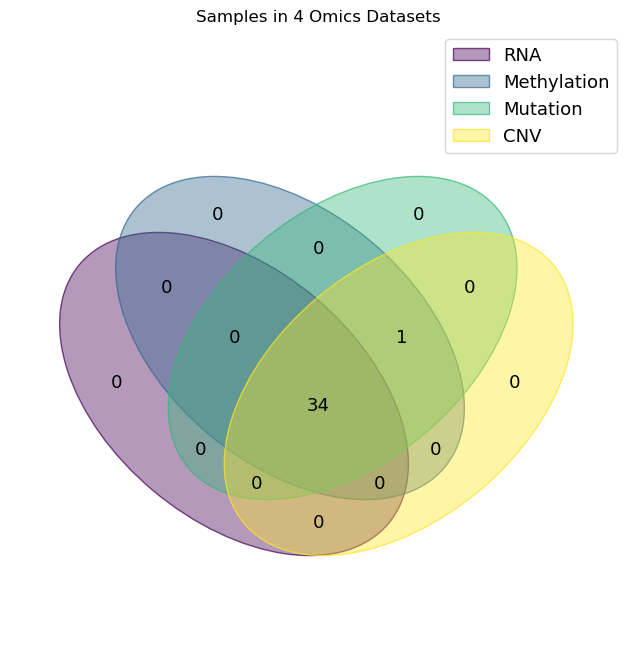

In [88]:
from venn import venn
import matplotlib.pyplot as plt

datasets = {
    "RNA": set(rna_table.columns),
    "Methylation": set(meth_table.columns),
    "Mutation": set(mut_table.columns),
    "CNV": set(cnv_table.columns)
}

venn(datasets)
plt.title("Samples in 4 Omics Datasets")
plt.show()